# Learning Localized Face Features with PEM — with a held-out test set (V2)

Same experiment as `PEM_Face_Feature_Learning.ipynb` (the **Predictive Entropy Maximization (PEM)**
network learning **localized, parts-based facial features** online, from a random initialization, in the
nonnegative antisparse domain $\mathcal{B}_{\max,+}$), **but with a proper train/test split**: we hold out
**50 Olivetti faces** and never use them for training. We then report reconstruction relative error on
**both the training set and the held-out test set** for PEM and for the batch baselines (PCA, NMF), so the
generalization of the learned features can be read off directly.

*Protocol (identical to the Fashion-MNIST V2 notebook):* PEM is trained only on the training faces; the
linear read-out $A$ is fit on the **training** codes and then applied unchanged to the test codes; PCA/NMF
bases are fit on the **training** faces and applied to the test faces. This makes the test error a genuine
generalization measure. (The 50 test images share identities with the training set — this is an
image-level held-out reconstruction test, not a novel-identity test.)

In [1]:
import sys
sys.path.append("../../src")
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA, NMF
import predictive_entropy_face_nmf as _pem
from predictive_entropy_face_nmf import PredictiveEntropyFaceNMF
_pem.tqdm = lambda it, **k: it  # silence per-epoch progress bars for a clean notebook
np.random.seed(0)

## 1. Data: Olivetti faces (32×32, nonnegative) — held out 50 for test

Train: (1024, 350)  Test: (1024, 50)


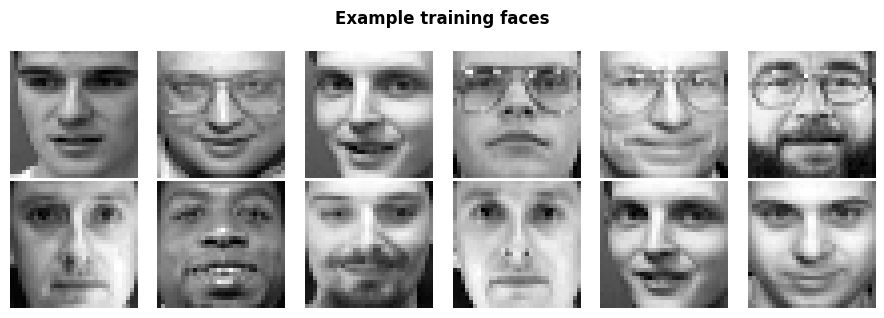

In [2]:
def load_faces(ts=32):
    faces, _ = fetch_olivetti_faces(return_X_y=True, shuffle=True, random_state=0)
    imgs = faces.reshape(-1, 64, 64)
    f = 64 // ts
    small = imgs.reshape(-1, ts, f, ts, f).mean(axis=(2, 4))
    return small.reshape(small.shape[0], -1).T.astype(np.float64)  # (pixels, samples)

TS = 32
IMG = (TS, TS)
Xall = load_faces(TS)                                  # (1024, 400)

N_test = 50
perm = np.random.RandomState(0).permutation(Xall.shape[1])
test_idx, train_idx = perm[:N_test], perm[N_test:]
X      = Xall[:, train_idx]                             # 350 training faces  (pixels x samples)
X_test = Xall[:, test_idx]                              # 50 held-out test faces
print("Train:", X.shape, " Test:", X_test.shape)

fig, ax = plt.subplots(2, 6, figsize=(9, 3.2))
for a, i in zip(ax.ravel(), np.random.choice(X.shape[1], 12, replace=False)):
    a.imshow(X[:, i].reshape(IMG), cmap="gray"); a.axis("off")
fig.suptitle("Example training faces", fontweight="bold"); plt.tight_layout(); plt.show()

## 2. Train the PEM network — online, local plasticity, **live feature plotting**

Per sample: (i) fast **neural dynamics** infer a nonnegative bounded activity $y\in[0,1]^K$ balancing a
predictive drive $\gamma\lVert y-Wx\rVert^2$ against adaptive lateral decorrelation; (ii) a **local
error-driven Hebbian rule** updates the feedforward weights, $W\mathrel{+}=\eta\,(y-Wx)x^\top$, projected
nonnegative, with a slowly decaying $\eta$. $W=$`None` uses the **random** nonnegative initialization.
Training uses the **350 training faces only**.

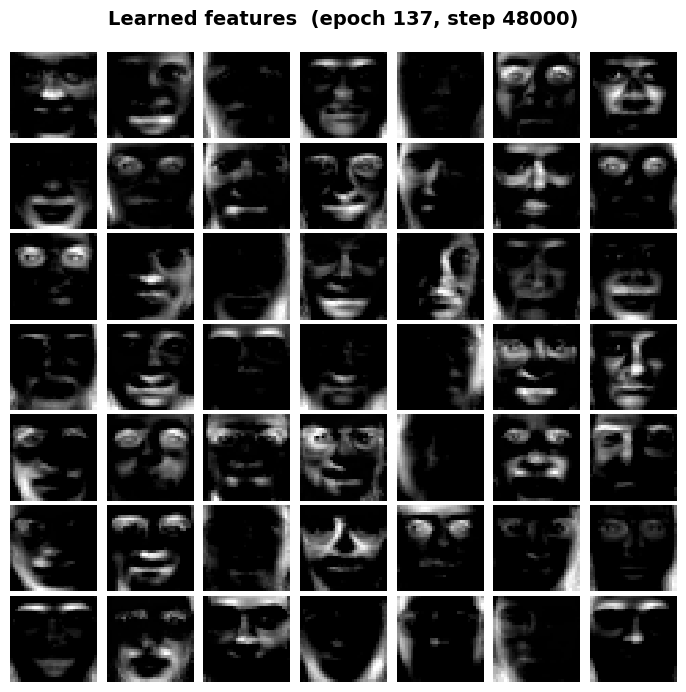

Training done. W nonnegative: True


In [3]:
K = 49  # number of feature units
model = PredictiveEntropyFaceNMF(
    n_sources=K, presumed_domain="nnantisparse",
    gamma_predictive=30.0, epsilon=2e-3, lambda_lateral=0.99,
    lr_W=5e-5, lr_W_rule="divide_by_index", lr_W_decay_divider=60000,
    neural_lr_start=0.1, neural_lr_stop=1e-2, neural_dynamics_iterations=200,
    W=None,                       # <- random, data-independent initialization
    image_shape=IMG, project_W_nonnegative=True,
    plot_debug_during_training=True, debug_iteration_point=12000/2,  # live view
    seed=7,
)
model.fit(X, n_epochs=150, shuffle_samples=True)
print("Training done. W nonnegative:", bool((model.W >= 0).all()))

In [4]:
model.W.shape, X.shape

((49, 1024), (1024, 350))

## 3. Inference & reconstruction — training **and** held-out test error

The read-out $A$ is fit on the **training** codes only, then applied to both splits.

In [5]:
Y = model.infer_codes(X)                                    # PEM codes for the TRAINING faces
A = (X @ Y.T) @ np.linalg.inv(Y @ Y.T + 1e-6 * np.eye(K))   # least-squares read-out fit on TRAIN codes
Y_te = model.infer_codes(X_test)                            # encode the 50 HELD-OUT test faces
pem_relerr      = np.linalg.norm(X      - A @ Y   ) / np.linalg.norm(X)        # TRAIN reconstruction
pem_relerr_test = np.linalg.norm(X_test - A @ Y_te) / np.linalg.norm(X_test)   # TEST recon (same read-out A)

usage = Y.var(axis=1)
Yc = Y - Y.mean(1, keepdims=True); sd = Y.std(1) + 1e-12
corr = (Yc @ Yc.T) / Y.shape[1] / np.outer(sd, sd)
off = np.abs(corr[~np.eye(K, dtype=bool)]).mean()
print("Active units: %d / %d | recon rel.err  train: %.3f  test: %.3f | mean |off-diag code corr|: %.3f"
      % (int((usage > 1e-6).sum()), K, pem_relerr, pem_relerr_test, off))

Active units: 49 / 49 | recon rel.err  train: 0.084  test: 0.096 | mean |off-diag code corr|: 0.261


## 4. The learned dictionary — 49 feedforward features (rows of $W$)

The network organizes into **localized facial parts** — eye pairs, mouths, eyebrows, nose/cheek
structure — together with holistic face templates.

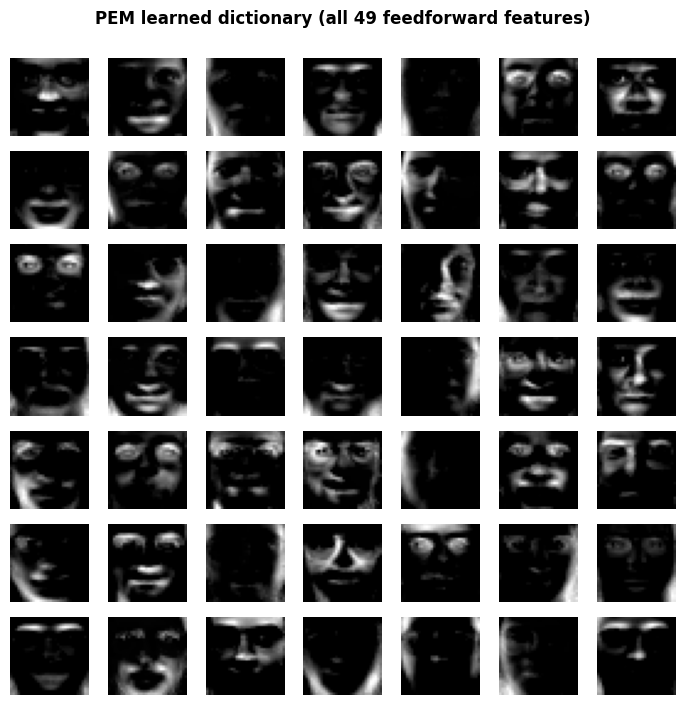

In [6]:
def grid(rows, shape, title, ncols=7, figsize=None):
    n = len(rows); nrows = int(np.ceil(n / ncols))
    fig, ax = plt.subplots(nrows, ncols, figsize=figsize or (ncols, nrows))
    for a in ax.ravel(): a.axis("off")
    for a, r in zip(ax.ravel(), rows):
        im = r.reshape(shape); im = (im - im.min()) / (np.ptp(im) + 1e-9)
        a.imshow(im, cmap="gray")
    fig.suptitle(title, fontweight="bold", y=1.0); plt.tight_layout(); plt.show()

grid(model.W, IMG, "PEM learned dictionary (all 49 feedforward features)")

### The most localized features (highest Hoyer sparsity) — clear facial parts

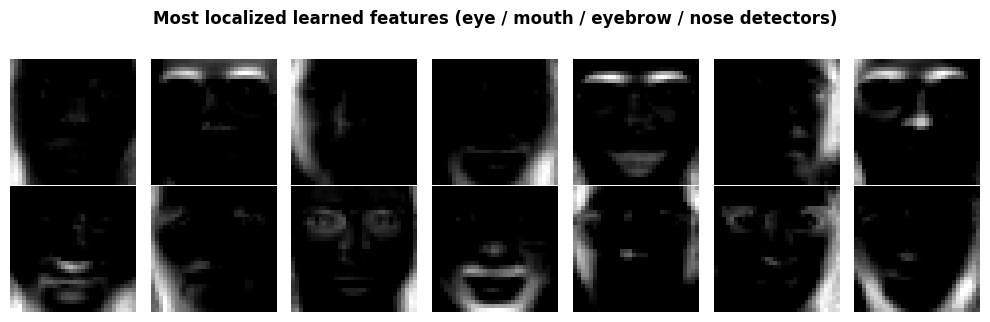

In [7]:
def hoyer(M):
    n = M.shape[1]; l1 = np.abs(M).sum(1); l2 = np.sqrt((M ** 2).sum(1)) + 1e-12
    return (np.sqrt(n) - l1 / l2) / (np.sqrt(n) - 1)

parts_order = np.argsort(-hoyer(model.W))
grid(model.W[parts_order][:14], IMG,
     "Most localized learned features (eye / mouth / eyebrow / nose detectors)",
     ncols=7, figsize=(10, 3.2))

## 5. Reconstructions of **held-out test faces** from the nonnegative code

These faces were never seen during training; they are encoded with the trained network and decoded with
the train-fit read-out.

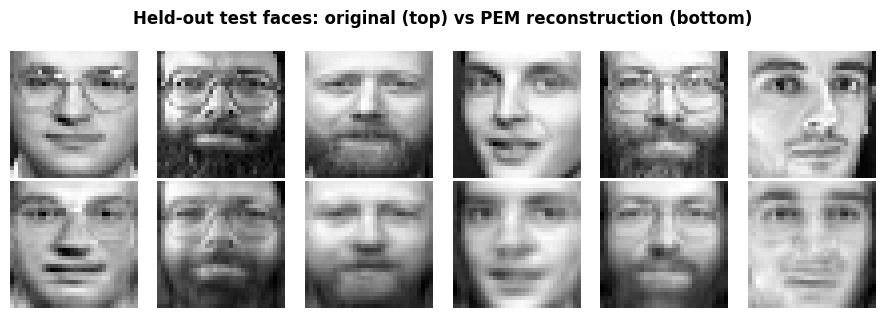

In [8]:
Xhat_te = A @ Y_te
idx = np.random.RandomState(1).choice(X_test.shape[1], 6, replace=False)
fig, ax = plt.subplots(2, 6, figsize=(9, 3.2))
for j, i in enumerate(idx):
    ax[0, j].imshow(X_test[:, i].reshape(IMG), cmap="gray"); ax[0, j].axis("off")
    ax[1, j].imshow(Xhat_te[:, i].reshape(IMG), cmap="gray"); ax[1, j].axis("off")
fig.suptitle("Held-out test faces: original (top) vs PEM reconstruction (bottom)", fontweight="bold")
plt.tight_layout(); plt.show()

## 6. Comparison with classical baselines (PCA, NMF) — train and test

PCA/NMF are offline batch methods fit on the **training** faces; PEM is fully online with local plasticity
and a random initialization. We compare reconstruction on both splits.

/opt/homebrew/anaconda3/envs/standardml/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 1000 reached. Increase it to improve convergence.
  warnings.warn(


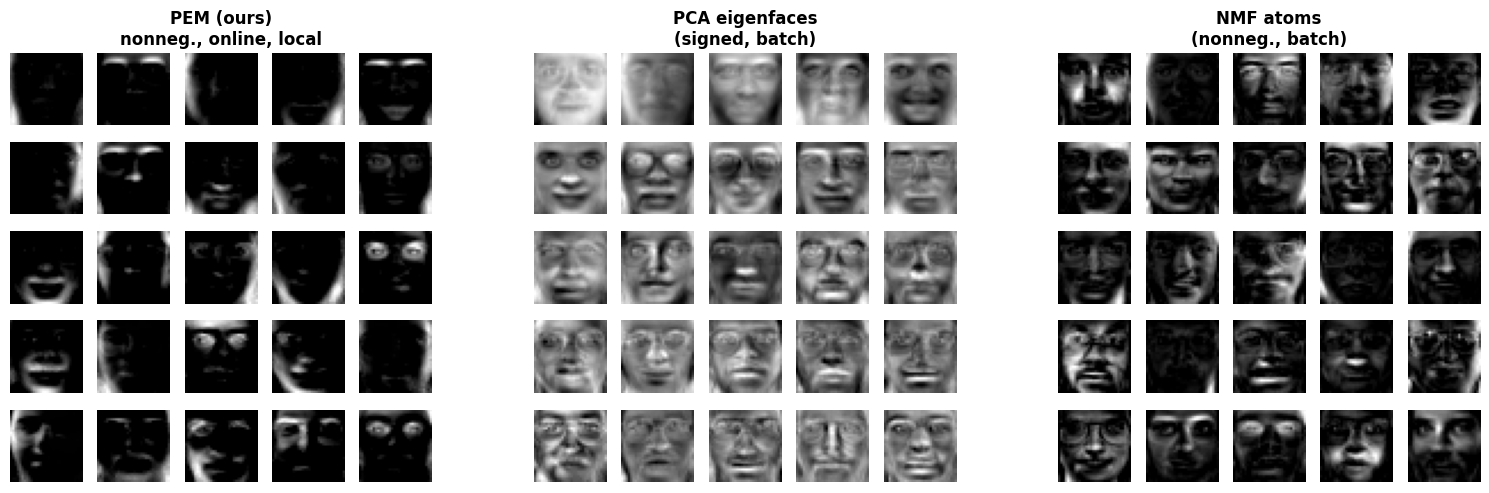

Reconstruction relative error (k=49, Olivetti faces) — 350 train / 50 test:
                                 train rel-err  test rel-err
PEM (ours, online, random init)          0.084         0.096
PCA (batch)                              0.072         0.084
NMF (batch)                              0.077         0.089

Fraction of nonnegative feature entries:  PEM: 1.00   PCA: 0.50   NMF: 1.00


,train rel-err,test rel-err
"PEM (ours, online, random init)",0.084,0.096
PCA (batch),0.072,0.084
NMF (batch),0.077,0.089


In [9]:
pca = PCA(n_components=K, random_state=0).fit(X.T)
pca_relerr      = np.linalg.norm(X      - pca.inverse_transform(pca.transform(X.T)).T)      / np.linalg.norm(X)
pca_relerr_test = np.linalg.norm(X_test - pca.inverse_transform(pca.transform(X_test.T)).T) / np.linalg.norm(X_test)
nmf = NMF(n_components=K, init="nndsvda", max_iter=1000, random_state=0, tol=1e-6)
Hn = nmf.fit_transform(X.T)
Hn_te = nmf.transform(X_test.T)                             # test codes with the FIXED (train) NMF basis
nmf_relerr      = np.linalg.norm(X      - (Hn    @ nmf.components_).T) / np.linalg.norm(X)
nmf_relerr_test = np.linalg.norm(X_test - (Hn_te @ nmf.components_).T) / np.linalg.norm(X_test)

n = 25; nc = 5
fig, axes = plt.subplots(nc, nc * 3 + 2, figsize=(15, 5))
for a in axes.ravel(): a.axis("off")
def fill(col0, rows):
    for t in range(n):
        a = axes[t // nc, col0 + t % nc]
        im = rows[t].reshape(IMG); im = (im - im.min()) / (np.ptp(im) + 1e-9)
        a.imshow(im, cmap="gray")
fill(0, model.W[parts_order][:n]); fill(nc + 1, pca.components_[:n]); fill(2 * nc + 2, nmf.components_[:n])
axes[0, nc // 2].set_title("PEM (ours)\nnonneg., online, local", fontweight="bold")
axes[0, nc + 1 + nc // 2].set_title("PCA eigenfaces\n(signed, batch)", fontweight="bold")
axes[0, 2 * nc + 2 + nc // 2].set_title("NMF atoms\n(nonneg., batch)", fontweight="bold")
plt.tight_layout(); plt.show()

import pandas as pd
recon_tbl = pd.DataFrame(
    {"train rel-err": [pem_relerr, pca_relerr, nmf_relerr],
     "test rel-err":  [pem_relerr_test, pca_relerr_test, nmf_relerr_test]},
    index=["PEM (ours, online, random init)", "PCA (batch)", "NMF (batch)"]).round(3)
print("Reconstruction relative error (k=49, Olivetti faces) — 350 train / 50 test:")
print(recon_tbl.to_string())
print("\nFraction of nonnegative feature entries:  PEM: %.2f   PCA: %.2f   NMF: %.2f"
      % ((model.W >= 0).mean(), (pca.components_ >= 0).mean(), (nmf.components_ >= 0).mean()))
recon_tbl

## 7. Findings

- With a **random, data-independent initialization** and training on **350 faces only**, the PEM network
  learns **localized, parts-based facial features** (eye pairs, mouths, eyebrows, nose/cheek structure)
  plus holistic templates — the classical NMF "parts of objects" phenomenon, obtained **online** with a
  local error-driven rule and adaptive lateral inhibition.
- **The features generalize:** reconstruction of the **50 held-out test faces** is essentially as good as
  on the training faces (see the table), and PEM's test error is **competitive with batch PCA/NMF** — with
  a small train↔test gap for every method, indicating the learned codes are not overfit to the training
  images. PEM's features remain 100% nonnegative.
- The parts emerge from the model's **decorrelation** (correlative-entropy) term as the feedforward weights
  settle (decaying learning rate); all 49 units stay active.